In [1]:
print("hello")

hello


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_df = pd.read_csv('/content/mnist_train.csv')
test_df = pd.read_csv('/content/mnist_test.csv')

X_train = train_df.iloc[:, 1:].values
y_train = train_df.iloc[:, 0].values
X_test = test_df.iloc[:, 1:].values
y_test = test_df.iloc[:, 0].values

num_samples = X_train.shape[0] + X_test.shape[0]
unique_labels, label_count = np.unique(y_train, return_counts=True)
num_classes = len(unique_labels)
image_dims = (28, 28)

print(f"Number of samples: {num_samples}")
print(f"Number of classes: {num_classes}")
print(f"Image dimensions: {image_dims}")

print(f"Unique labels: {unique_labels}")
print("Number of samples per label:")
for label, count in zip(unique_labels, label_count):
    print(f"{label}: {count}")

Number of samples: 3962
Number of classes: 10
Image dimensions: (28, 28)
Unique labels: [0 1 2 3 4 5 6 7 8 9]
Number of samples per label:
0: 309
1: 363
2: 326
3: 318
4: 357
5: 292
6: 328
7: 356
8: 294
9: 316


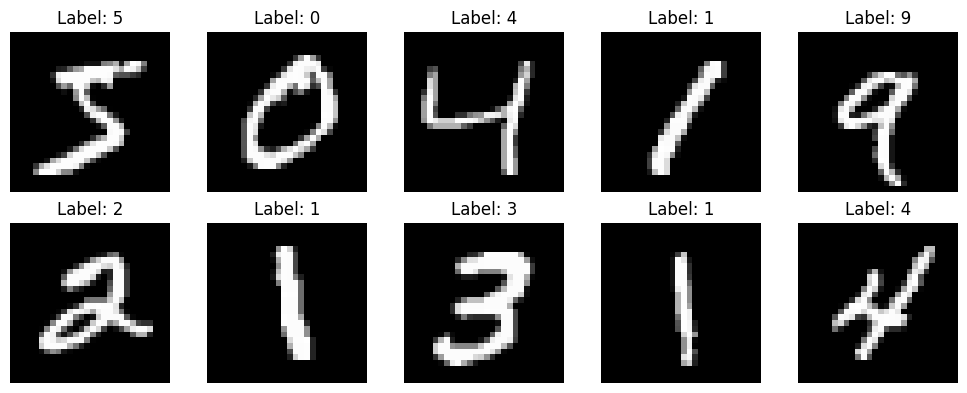

In [3]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [4]:
X_train = X_train / 255.0
X_test = X_test / 255.0
print(f"Normalized X_train min/max: {X_train.min()} / {X_train.max()}")
print(f"Normalized X_test min/max: {X_test.min()} / {X_test.max()}")

Normalized X_train min/max: 0.0 / 1.0
Normalized X_test min/max: 0.0 / 1.0


In [5]:
from sklearn.decomposition import PCA

pca_all = PCA()
pca_all.fit(X_train)

cumsum = np.cumsum(pca_all.explained_variance_ratio_)

n_90 = np.argmax(cumsum >= 0.90) + 1
n_95 = np.argmax(cumsum >= 0.95) + 1
n_99 = np.argmax(cumsum >= 0.99) + 1

print(f"Components for 90% variance: {n_90}")
print(f"Components for 95% variance: {n_95}")
print(f"Components for 99% variance: {n_99}")

Components for 90% variance: 83
Components for 95% variance: 145
Components for 99% variance: 314


In [6]:
pca_2 = PCA(n_components=2)
X_train_pca_2 = pca_2.fit_transform(X_train)

pca_50 = PCA(n_components=50)
X_train_pca_50 = pca_50.fit_transform(X_train)
X_test_pca_50 = pca_50.transform(X_test)

print(f"2D PCA shape: {X_train_pca_2.shape}")
print(f"50D PCA shape: {X_train_pca_50.shape}")

2D PCA shape: (3259, 2)
50D PCA shape: (3259, 50)


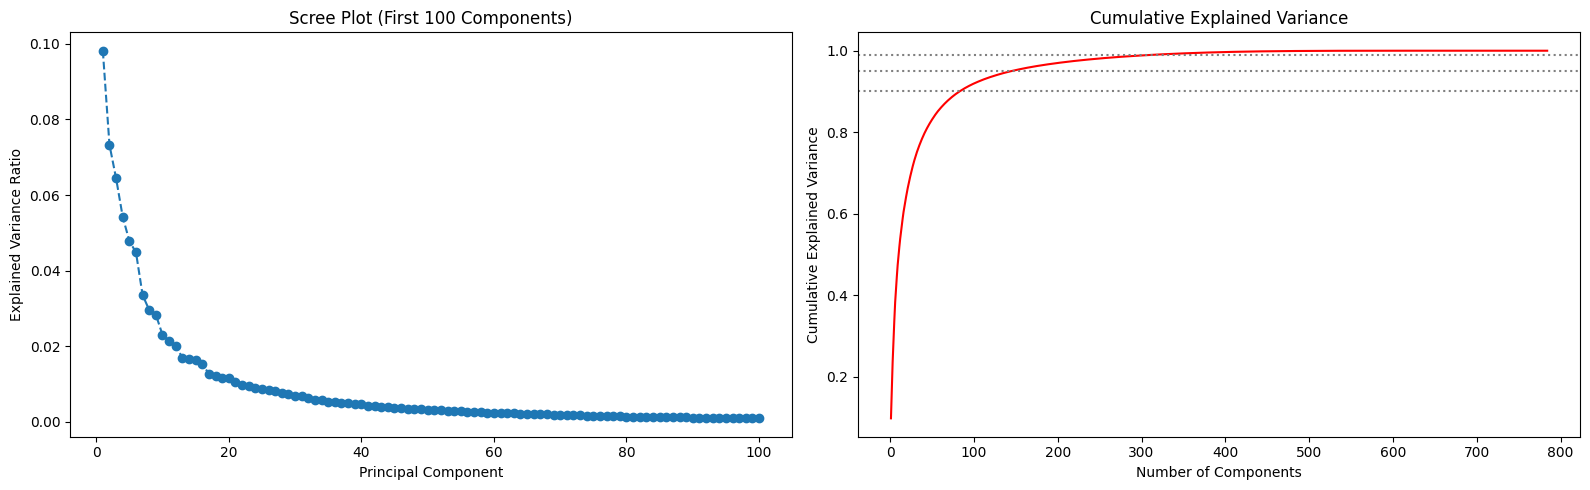

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.plot(range(1, len(pca_all.explained_variance_ratio_[:100]) + 1), pca_all.explained_variance_ratio_[:100], marker='o', linestyle='--')
ax1.set_title('Scree Plot (First 100 Components)')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')

ax2.plot(range(1, len(cumsum) + 1), cumsum, color='red')
ax2.axhline(y=0.90, color='gray', linestyle=':')
ax2.axhline(y=0.95, color='gray', linestyle=':')
ax2.axhline(y=0.99, color='gray', linestyle=':')
ax2.set_title('Cumulative Explained Variance')
ax2.set_xlabel('Number of Components')
ax2.set_ylabel('Cumulative Explained Variance')

plt.tight_layout()
plt.show()

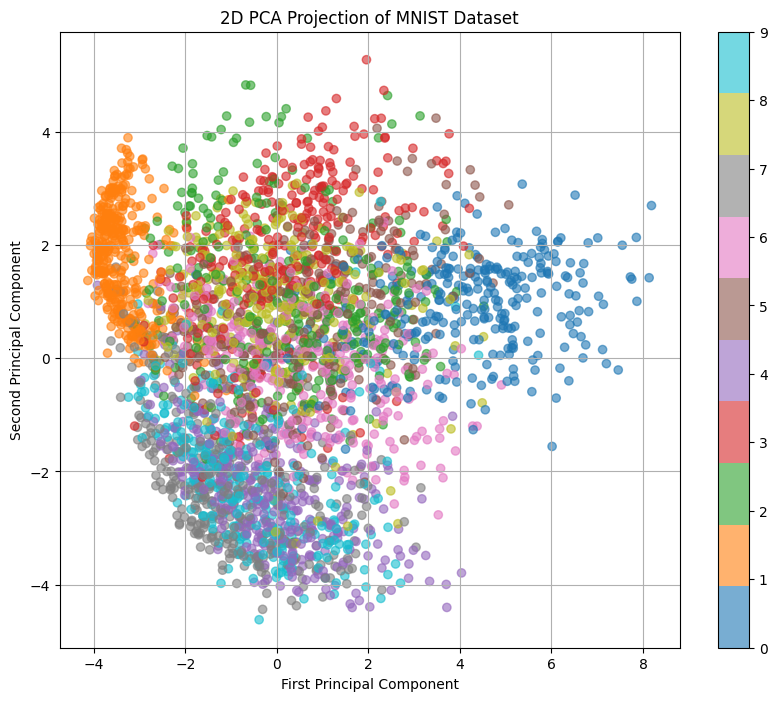

In [8]:
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_train_pca_2[:, 0], X_train_pca_2[:, 1], c=y_train, cmap='tab10', alpha=0.6)
plt.colorbar(scatter, ticks=range(10))
plt.title('2D PCA Projection of MNIST Dataset')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.grid(True)
plt.show()

Part C: t-SNE Visualization


In [9]:
from sklearn.manifold import TSNE

tsne_orig_30 = TSNE(n_components=2, perplexity=30, random_state=42)
X_train_tsne_orig_30 = tsne_orig_30.fit_transform(X_train)

tsne_pca_30 = TSNE(n_components=2, perplexity=30, random_state=42)
X_train_tsne_pca_30 = tsne_pca_30.fit_transform(X_train_pca_50)

tsne_pca_5 = TSNE(n_components=2, perplexity=5, random_state=42)
X_train_tsne_pca_5 = tsne_pca_5.fit_transform(X_train_pca_50)

tsne_pca_50 = TSNE(n_components=2, perplexity=50, random_state=42)
X_train_tsne_pca_50 = tsne_pca_50.fit_transform(X_train_pca_50)

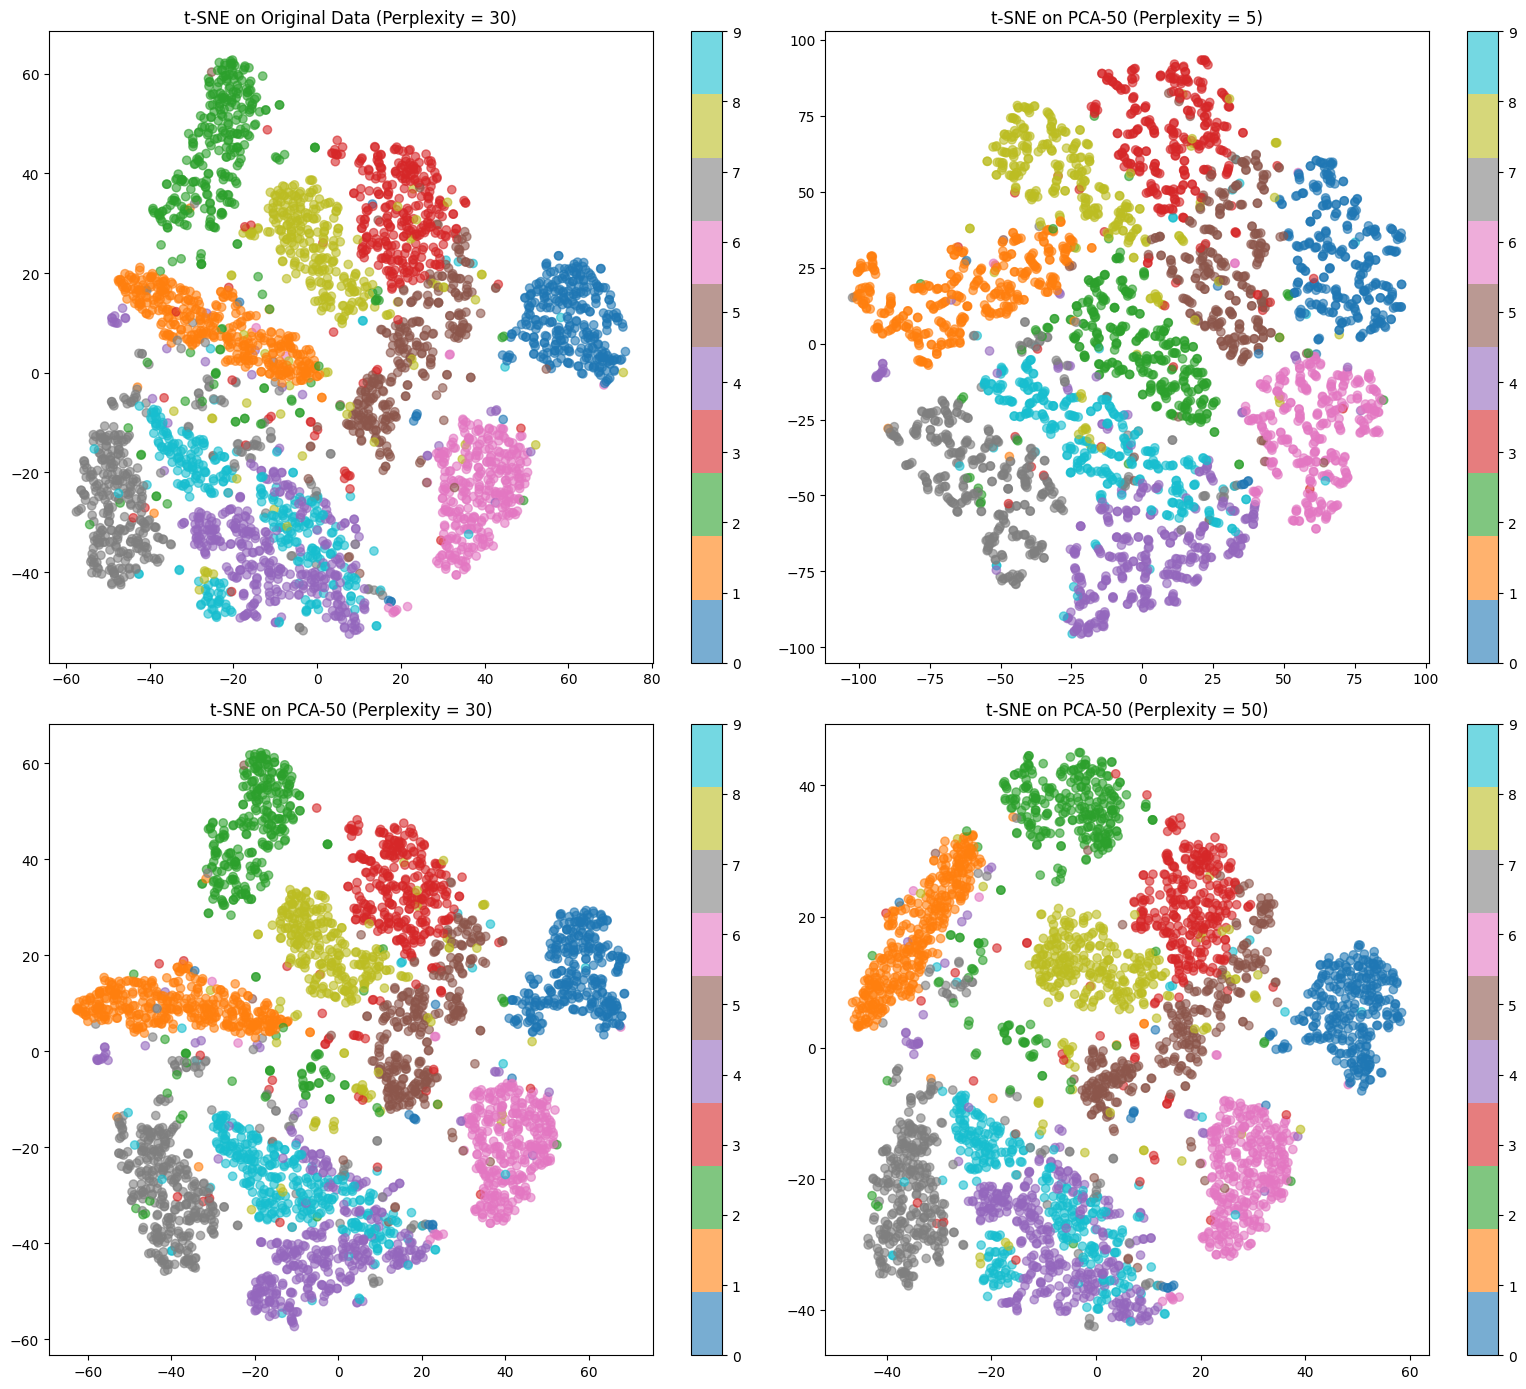

In [10]:
fig, axs = plt.subplots(2, 2, figsize=(16, 14))

sc0 = axs[0, 0].scatter(X_train_tsne_orig_30[:, 0], X_train_tsne_orig_30[:, 1], c=y_train, cmap='tab10', alpha=0.6)
axs[0, 0].set_title('t-SNE on Original Data (Perplexity = 30)')
fig.colorbar(sc0, ax=axs[0, 0])

sc1 = axs[0, 1].scatter(X_train_tsne_pca_5[:, 0], X_train_tsne_pca_5[:, 1], c=y_train, cmap='tab10', alpha=0.6)
axs[0, 1].set_title('t-SNE on PCA-50 (Perplexity = 5)')
fig.colorbar(sc1, ax=axs[0, 1])

sc2 = axs[1, 0].scatter(X_train_tsne_pca_30[:, 0], X_train_tsne_pca_30[:, 1], c=y_train, cmap='tab10', alpha=0.6)
axs[1, 0].set_title('t-SNE on PCA-50 (Perplexity = 30)')
fig.colorbar(sc2, ax=axs[1, 0])

sc3 = axs[1, 1].scatter(X_train_tsne_pca_50[:, 0], X_train_tsne_pca_50[:, 1], c=y_train, cmap='tab10', alpha=0.6)
axs[1, 1].set_title('t-SNE on PCA-50 (Perplexity = 50)')
fig.colorbar(sc3, ax=axs[1, 1])

plt.tight_layout()
plt.show()

Part D: Digit Recognition Analysis


In [11]:
import time
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import accuracy_score

lda = LDA()
X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)

start_time = time.time()
knn_original = KNeighborsClassifier(n_neighbors=5)
knn_original.fit(X_train, y_train)
train_time_orig = time.time() - start_time

start_time = time.time()
y_pred_original = knn_original.predict(X_test)
pred_time_orig = time.time() - start_time
accuracy_original = accuracy_score(y_test, y_pred_original)

start_time = time.time()
knn_pca = KNeighborsClassifier(n_neighbors=5)
knn_pca.fit(X_train_pca_50, y_train)
train_time_pca = time.time() - start_time

start_time = time.time()
y_pred_pca = knn_pca.predict(X_test_pca_50)
pred_time_pca = time.time() - start_time
accuracy_pca = accuracy_score(y_test, y_pred_pca)

start_time = time.time()
knn_lda = KNeighborsClassifier(n_neighbors=5)
knn_lda.fit(X_train_lda, y_train)
train_time_lda = time.time() - start_time

start_time = time.time()
y_pred_lda = knn_lda.predict(X_test_lda)
pred_time_lda = time.time() - start_time
accuracy_lda = accuracy_score(y_test, y_pred_lda)

In [12]:
print("-"*50)
print('Performance Results:')
print(f"Original data: {X_train.shape[1]} dimensions, Accuracy: {accuracy_original:.4f}, Train Time: {train_time_orig:.4f}s, Predict Time: {pred_time_orig:.4f}s")
print(f"PCA data: {X_train_pca_50.shape[1]} dimensions, Accuracy: {accuracy_pca:.4f}, Train Time: {train_time_pca:.4f}s, Predict Time: {pred_time_pca:.4f}s")
print(f"LDA data: {X_train_lda.shape[1]} dimensions, Accuracy: {accuracy_lda:.4f}, Train Time: {train_time_lda:.4f}s, Predict Time: {pred_time_lda:.4f}s")

print("-"*50)
print('Memory Usage:')
print(f"Original data: {X_train.nbytes / (1024**2):.4f} MB")
print(f"PCA data: {X_train_pca_50.nbytes / (1024**2):.4f} MB")
print(f"LDA data: {X_train_lda.nbytes / (1024**2):.4f} MB")
print("-"*50)

--------------------------------------------------
Performance Results:
Original data: 784 dimensions, Accuracy: 0.8862, Train Time: 0.0297s, Predict Time: 0.2174s
PCA data: 50 dimensions, Accuracy: 0.9147, Train Time: 0.0014s, Predict Time: 0.0195s
LDA data: 9 dimensions, Accuracy: 0.8065, Train Time: 0.0061s, Predict Time: 0.0235s
--------------------------------------------------
Memory Usage:
Original data: 19.4935 MB
PCA data: 1.2432 MB
LDA data: 0.2238 MB
--------------------------------------------------
